# Stage 3 – Classification Head Experiments

In [10]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

old_model = keras.models.load_model(
    "/kaggle/working/best_efficientnet_b0_finetuned.keras"
)

base_model = old_model.get_layer("efficientnetb0")
base_model.trainable = False

inputs = keras.Input(shape=(224, 224, 3))

x = base_model(inputs, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(256, activation="relu")(x)
x = layers.Dropout(0.4)(x)
outputs = layers.Dense(5, activation="softmax")(x)

model_new = keras.Model(inputs, outputs)

model_new.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.0001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model_new.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 5)              │         1,285 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,378,792 (16.70 MB)

 Trainable params: 329,221 (1.26 MB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [11]:
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau

callbacks = [
    ModelCheckpoint(
        "/kaggle/working/best_efficientnet_b0_new_head.keras",
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),
    EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-7,
        verbose=1
    )
]

history_new = model_new.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=callbacks
)

Epoch 1/10
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 104ms/step - accuracy: 0.5954 - loss: 1.0820
Epoch 1: val_loss improved from None to 0.85544, saving model to /kaggle/working/best_efficientnet_b0_new_head.keras

Epoch 1: finished saving model to /kaggle/working/best_efficientnet_b0_new_head.keras
141/141 ━━━━━━━━━━━━━━━━━━━━ 46s 193ms/step - accuracy: 0.6061 - loss: 0.9957 - val_accuracy: 0.6235 - val_loss: 0.8554 - learning_rate: 1.0000e-04
Epoch 2/10
139/141 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.6904 - loss: 0.7534
Epoch 2: val_loss improved from 0.85544 to 0.77346, saving model to /kaggle/working/best_efficientnet_b0_new_head.keras

Epoch 2: finished saving model to /kaggle/working/best_efficientnet_b0_new_head.keras
141/141 ━━━━━━━━━━━━━━━━━━━━ 6s 45ms/step - accuracy: 0.6736 - loss: 0.7663 - val_accuracy: 0.6671 - val_loss: 0.7735 - learning_rate: 1.0000e-04
Epoch 3/10
139/141 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - accuracy: 0.7231 - loss: 0.6790
Epoch 3: val_loss improved from 0

23/23 ━━━━━━━━━━━━━━━━━━━━ 13s 315ms/step
                  precision    recall  f1-score   support

           No DR       0.94      0.96      0.95       361
            Mild       0.45      0.45      0.45        74
        Moderate       0.72      0.63      0.67       200
          Severe       0.38      0.56      0.45        39
Proliferative DR       0.43      0.42      0.43        59

        accuracy                           0.75       733
       macro avg       0.58      0.60      0.59       733
    weighted avg       0.76      0.75      0.76       733



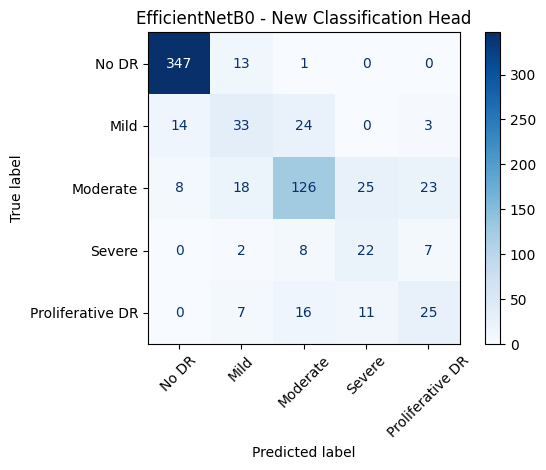

In [12]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow import keras
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

best_model = keras.models.load_model(
    "/kaggle/working/best_efficientnet_b0_new_head.keras"
)

y_prob = best_model.predict(val_ds, verbose=1)
y_pred = np.argmax(y_prob, axis=1)

class_names = [
    "No DR",
    "Mild",
    "Moderate",
    "Severe",
    "Proliferative DR"
]

print(classification_report(
    y_val,
    y_pred,
    labels=[0, 1, 2, 3, 4],
    target_names=class_names,
    zero_division=0
))

cm = confusion_matrix(
    y_val,
    y_pred,
    labels=[0, 1, 2, 3, 4]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(xticks_rotation=45, cmap="Blues")
plt.title("EfficientNetB0 - New Classification Head")
plt.tight_layout()
plt.show()


In [13]:
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.callbacks import (
    ModelCheckpoint,
    EarlyStopping,
    ReduceLROnPlateau
)

model_ft2 = keras.models.load_model(
    "/kaggle/working/best_efficientnet_b0_new_head.keras"
)

base_model = model_ft2.get_layer("efficientnetb0")
base_model.trainable = True

                                      
for layer in base_model.layers[:-30]:
    layer.trainable = False

                                        
for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

model_ft2.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

callbacks = [
    ModelCheckpoint(
        "/kaggle/working/best_efficientnet_b0_final.keras",
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),
    EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=1,
        min_lr=1e-7,
        verbose=1
    )
]

history_ft2 = model_ft2.fit(
    train_ds,
    validation_data=val_ds,
    epochs=8,
    callbacks=callbacks
)

Epoch 1/8
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 122ms/step - accuracy: 0.8146 - loss: 0.4908
Epoch 1: val_loss improved from None to 0.65814, saving model to /kaggle/working/best_efficientnet_b0_final.keras

Epoch 1: finished saving model to /kaggle/working/best_efficientnet_b0_final.keras
141/141 ━━━━━━━━━━━━━━━━━━━━ 51s 211ms/step - accuracy: 0.7962 - loss: 0.5166 - val_accuracy: 0.7462 - val_loss: 0.6581 - learning_rate: 1.0000e-05
Epoch 2/8
140/141 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - accuracy: 0.8161 - loss: 0.4887
Epoch 2: val_loss improved from 0.65814 to 0.62950, saving model to /kaggle/working/best_efficientnet_b0_final.keras

Epoch 2: finished saving model to /kaggle/working/best_efficientnet_b0_final.keras
141/141 ━━━━━━━━━━━━━━━━━━━━ 7s 51ms/step - accuracy: 0.8042 - loss: 0.5098 - val_accuracy: 0.7585 - val_loss: 0.6295 - learning_rate: 1.0000e-05
Epoch 3/8
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - accuracy: 0.8240 - loss: 0.4740
Epoch 3: val_loss did not improve from 0.62950



23/23 ━━━━━━━━━━━━━━━━━━━━ 14s 352ms/step
                  precision    recall  f1-score   support

           No DR       0.95      0.96      0.95       361
            Mild       0.48      0.42      0.45        74
        Moderate       0.71      0.66      0.68       200
          Severe       0.36      0.51      0.43        39
Proliferative DR       0.42      0.44      0.43        59

        accuracy                           0.76       733
       macro avg       0.58      0.60      0.59       733
    weighted avg       0.76      0.76      0.76       733



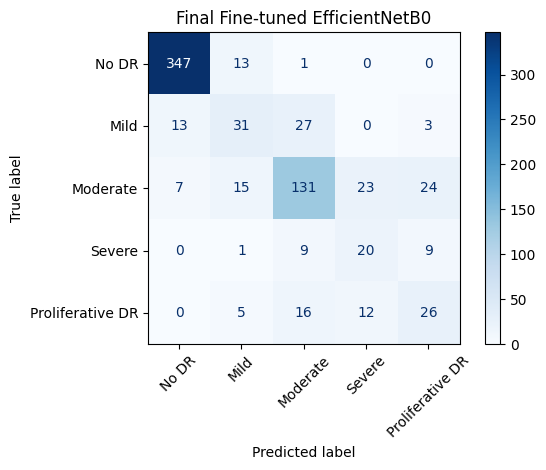

In [14]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow import keras
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

best_model = keras.models.load_model(
    "/kaggle/working/best_efficientnet_b0_final.keras"
)

y_prob = best_model.predict(val_ds, verbose=1)
y_pred = np.argmax(y_prob, axis=1)

class_names = [
    "No DR",
    "Mild",
    "Moderate",
    "Severe",
    "Proliferative DR"
]

print(classification_report(
    y_val,
    y_pred,
    labels=[0, 1, 2, 3, 4],
    target_names=class_names,
    zero_division=0
))

cm = confusion_matrix(
    y_val,
    y_pred,
    labels=[0, 1, 2, 3, 4]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(xticks_rotation=45, cmap="Blues")
plt.title("Final Fine-tuned EfficientNetB0")
plt.tight_layout()
plt.show()